# Feature Description and Matching
## Scale-invariant Feature Transform (SIFT)

Import the packages and load the image `Book.jpg`

In [9]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

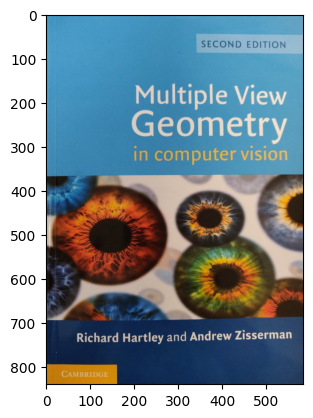

In [ ]:
# Load the reference image and fix its color order for display.
# cv2.imread() loads images in BGR order, but matplotlib expects RGB, so we
# split into channels and re-merge them in reversed (R, G, B) order to get
# correct colors when plotted with plt.imshow().
img = cv2.imread("Book.jpg")

# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img)
img = cv2.merge([r,g,b])
plt.imshow(img)

We'll start by converting the image to grayscale.

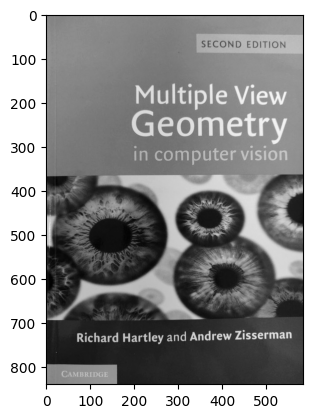

In [11]:
# Convert the image to grayscale.
# SIFT (like most classic feature detectors) operates on pixel intensity
# gradients, not color, so it expects a single-channel grayscale image as input
# rather than a 3-channel color image.
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
plt.imshow(gray, cmap = 'gray')

Now we will attempt to find the features and descriptors using [SIFT](https://docs.opencv.org/4.7.0/d7/d60/classcv_1_1SIFT.html). In OpenCV we will do it by first creating a SIFT object using `cv2.SIFT_create`, and then use the class method `detectAndCompute`.

In [ ]:
# Detect SIFT keypoints and compute their descriptors.
# Scale-Invariant Feature Transform (SIFT) finds distinctive "corner- like"
# points in the image (keypoints) and, for each one, a numeric descriptor
# summarizing the local image patch around it. Because these descriptors are
# designed to stay consistent under changes in scale, rotation, and (to some
# extent) illumination, they let us later match the same physical feature even
# if it appears at a different size or angle in a different image.
#   - cv2.SIFT_create() builds a SIFT detector object with default parameters.
#   - detectAndCompute(gray, None) does two things at once: it locates keypoints
#     in the grayscale image, and computes a descriptor vector for each one.
#     The second argument (None) is an optional mask restricting detection to
#     certain image regions. We don't need one here since we want to search
#     the whole image.
#   - 'kp' holds the keypoint locations/scale/orientation; 'des' holds the
#     corresponding numeric descriptor for each keypoint. It's 'des' that gets
#     compared between images during matching.
sift = cv2.SIFT_create()
kp, des = sift.detectAndCompute(gray, None) #Keypoints and descriptors.

To show the detected keypoints we use the function [`cv2.drawKeyPoints`](https://docs.opencv.org/4.7.0/d4/d5d/group__features2d__draw.html#ga5d2bafe8c1c45289bc3403a40fb88920). We scale the picture up by passing the argument `figsize`, so it's easier to see.

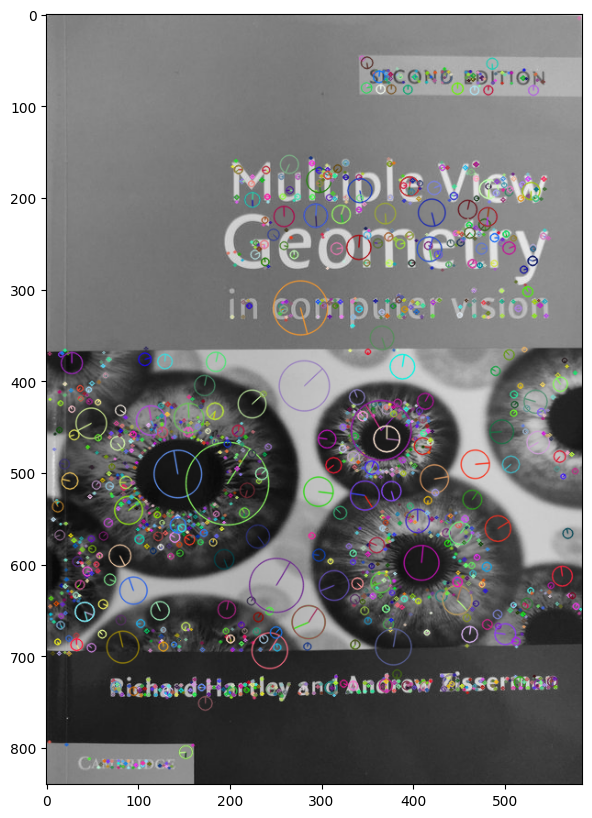

In [13]:
# Visualize the detected SIFT keypoints on the image.
# It's useful to see where the detector found its keypoints before trying to
# match them against another image, both to sanity-check that detection worked
# and to build intuition for what SIFT considers a "distinctive" feature
# (typically corners, blobs, and textured regions).
# cv2.drawKeypoints() overlays a marker for each keypoint onto a copy of the
# image. The DRAW_RICH_KEYPOINTS flag additionally draws each keypoint's
# detected scale (as a circle size) and orientation (as a radial line), not
# just its position. figsize=(10,10) simply enlarges the plotted figure so the
# many small keypoint markers are easier to see.
kp_img = cv2.drawKeypoints(gray, kp, img, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize = (10,10))
plt.imshow(kp_img)

Let's load the image `More_books.jpg` and convert it to grayscale.

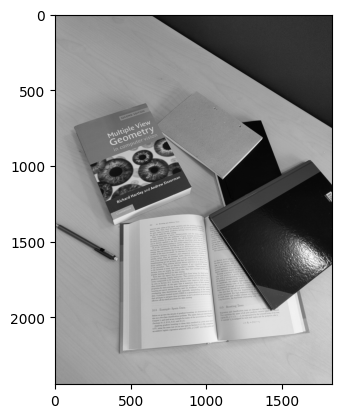

In [ ]:
# Load a second image containing multiple books and convert it to grayscale,
# exactly as before. To test feature matching, we need a second image that plausibly
# contains the same object (the book) so we can check whether SIFT can correctly
# re-identify it among distractors (the other books).
img2 = cv2.imread("More_books.jpg")
# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img2)
img2 = cv2.merge([r,g,b])

gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)
plt.imshow(gray2, cmap = 'gray')

We use the same SIFT method again to find the keypoints and descriptors of this image.

In [ ]:
# Detect SIFT keypoints and descriptors for the second image. To match features
# between the two images, we need a set of keypoints/descriptors for both. This
# repeats the exact same detectAndCompute() step as before, just on the new
# image (gray2).
kp2, des2 = sift.detectAndCompute(gray2, None)

Now that we have the descriptors of both images, let's see if we can match them and find the book from the first image in the second image.
For this example we use the **Brute Force Matcher** ([`cv2.BFMatcher`](https://docs.opencv.org/4.7.0/d3/da1/classcv_1_1BFMatcher.html)). We use the function `cv2.match` to find the matches.

In [16]:
# Match the descriptors between the two images using brute-force matching. Now
# that we have descriptor sets for both images, we need to find which keypoints
# in image 1 correspond to which keypoints in image 2 (i.e. which local patches
# look similar enough to be the "same" feature). cv2.BFMatcher() creates a
# Brute-Force matcher, which (with default settings) compares every descriptor
# in 'des' against every descriptor in 'des2' using a distance metric, and for
# each descriptor in the first image returns its single closest match in the
# second image. This exhaustive approach is simple and accurate, though slower
# than approximate methods (like FLANN) on very large descriptor sets.
bf = cv2.BFMatcher()
matches = bf.match(des, des2)

We use the function [`cv2.drawMatches`](https://docs.opencv.org/4.7.0/d4/d5d/group__features2d__draw.html#gad8f463ccaf0dc6f61083abd8717c261a) to display the result. We'd like to display the best of the matches. The matching is made using a distance measurement between the descriptor: The smaller the distance, the better the match. So we sort the `matches` array using the distance term and then we plot only the first 100 matches.

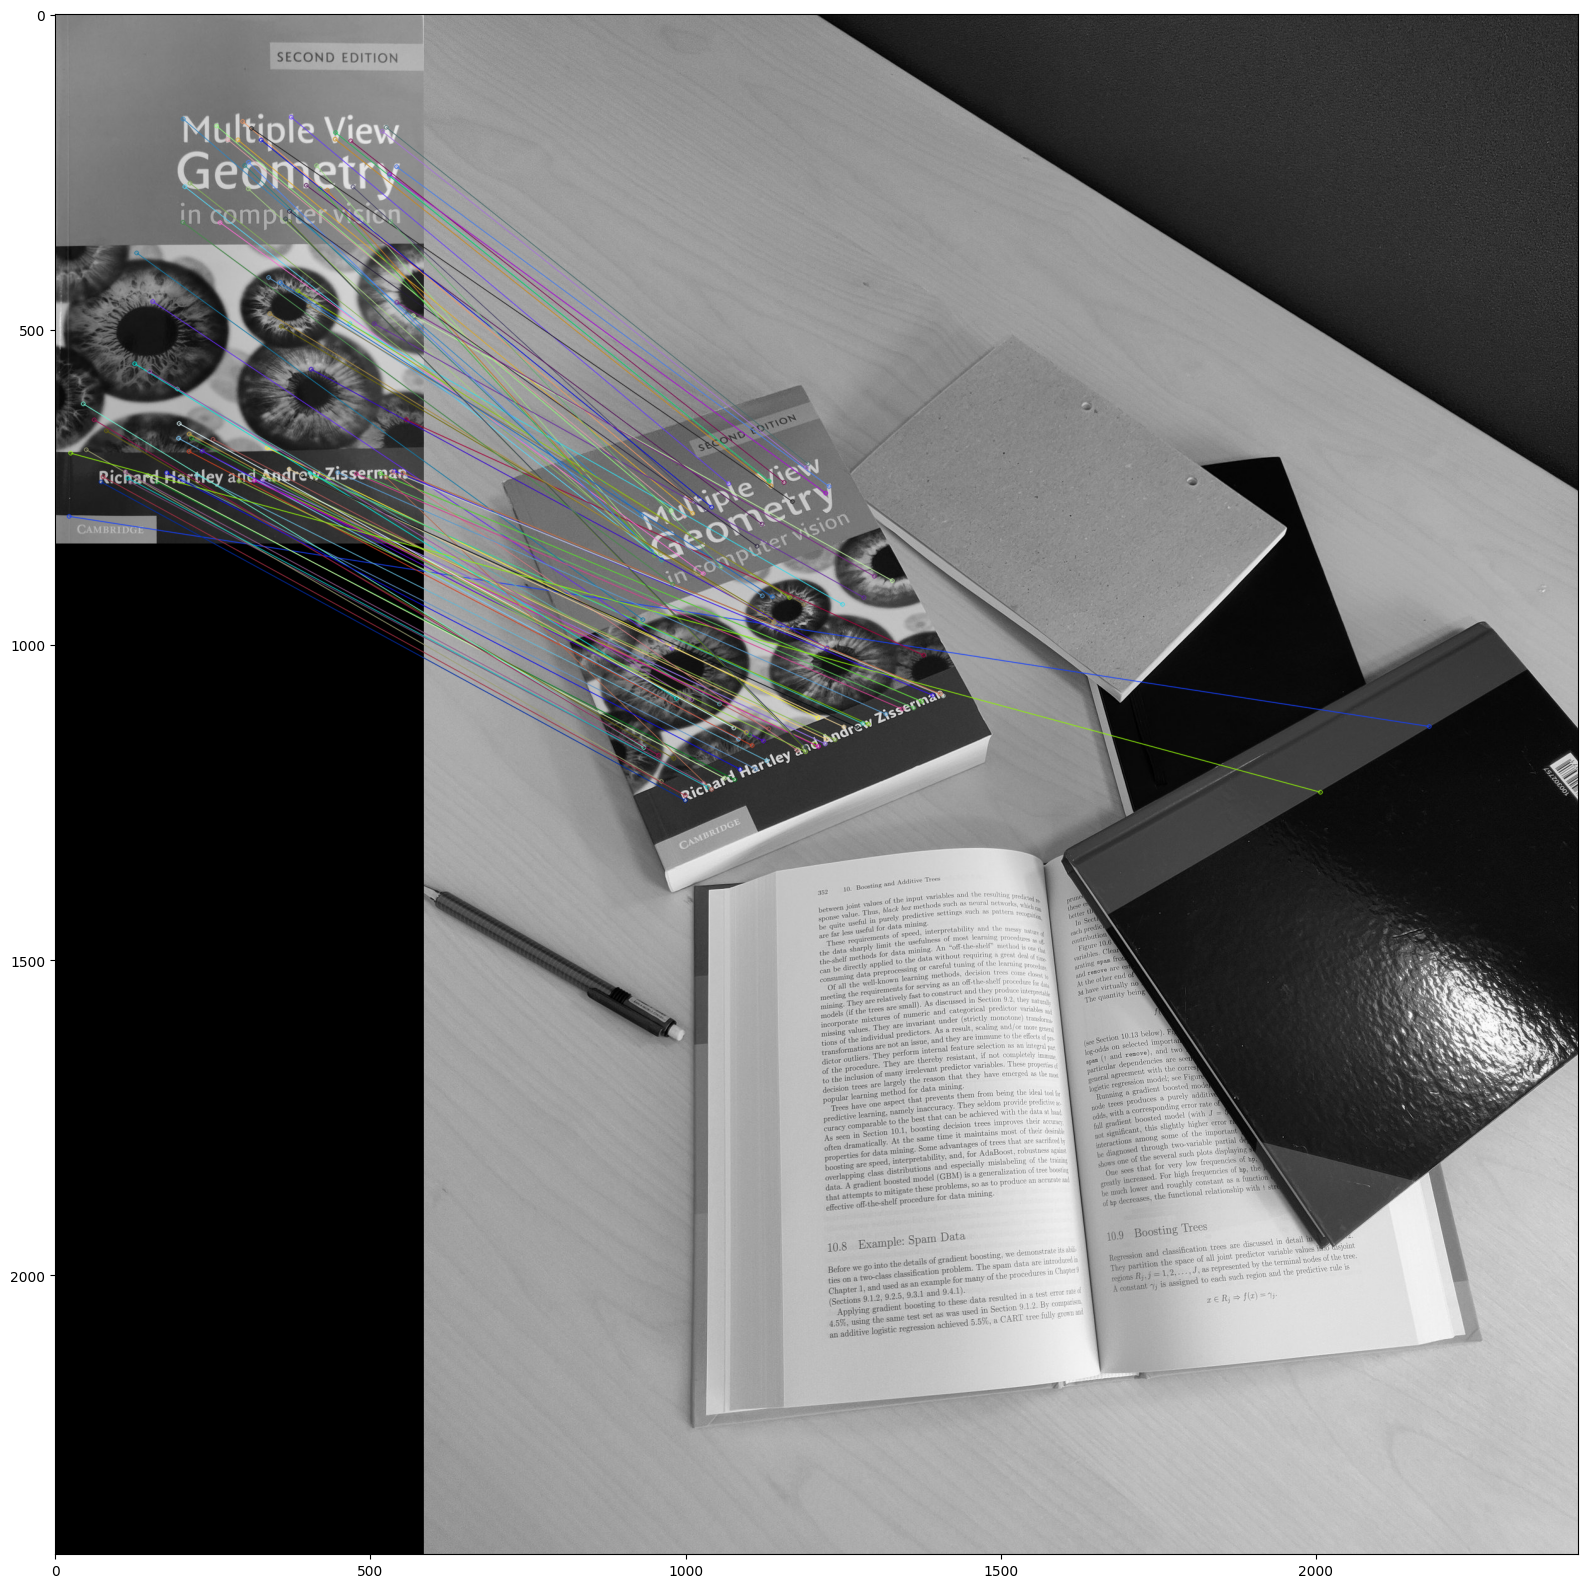

In [ ]:
# Sort matches by quality and visualize the best ones.
# Each match has a 'distance' value from the matcher; a smaller distance means
# the two descriptors are more similar (i.e. a stronger/more reliable match).
# Sorting ascending puts the best matches first. With potentially thousands of
# raw matches, many of which are weak or incorrect, restricting the visualization
# to only the top 100 (best/most confident) matches keeps the plot readable and
# focuses on the matches most likely to be genuinely correct.
# cv2.drawMatches() draws both images side by side and connects matched keypoints
# with lines. The flag DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS hides any
# keypoints that weren't part of the drawn matches, decluttering the visualization
# so only the actual matched pairs are shown. figsize=(20,20) enlarges the
# figure since we're now displaying two images side by side with many connecting lines.
matches = sorted(matches, key = lambda x:x.distance)

img3 = cv2.drawMatches(gray,kp,gray2,kp2,matches[:100],None,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize = (20,20))
plt.imshow(img3)

We see that most of the matches are correct, but with some outliers.

# Exercise 3
Using the same two images, try to use Oriented BRIEF ([ORB](https://docs.opencv.org/4.7.0/db/d95/classcv_1_1ORB.html)) instead of SIFT to find the keypoints and the descriptors. Does one of these methods give a better result than the other? Try plotting more than just the best 100 matches and see if there is a difference between the two methods.

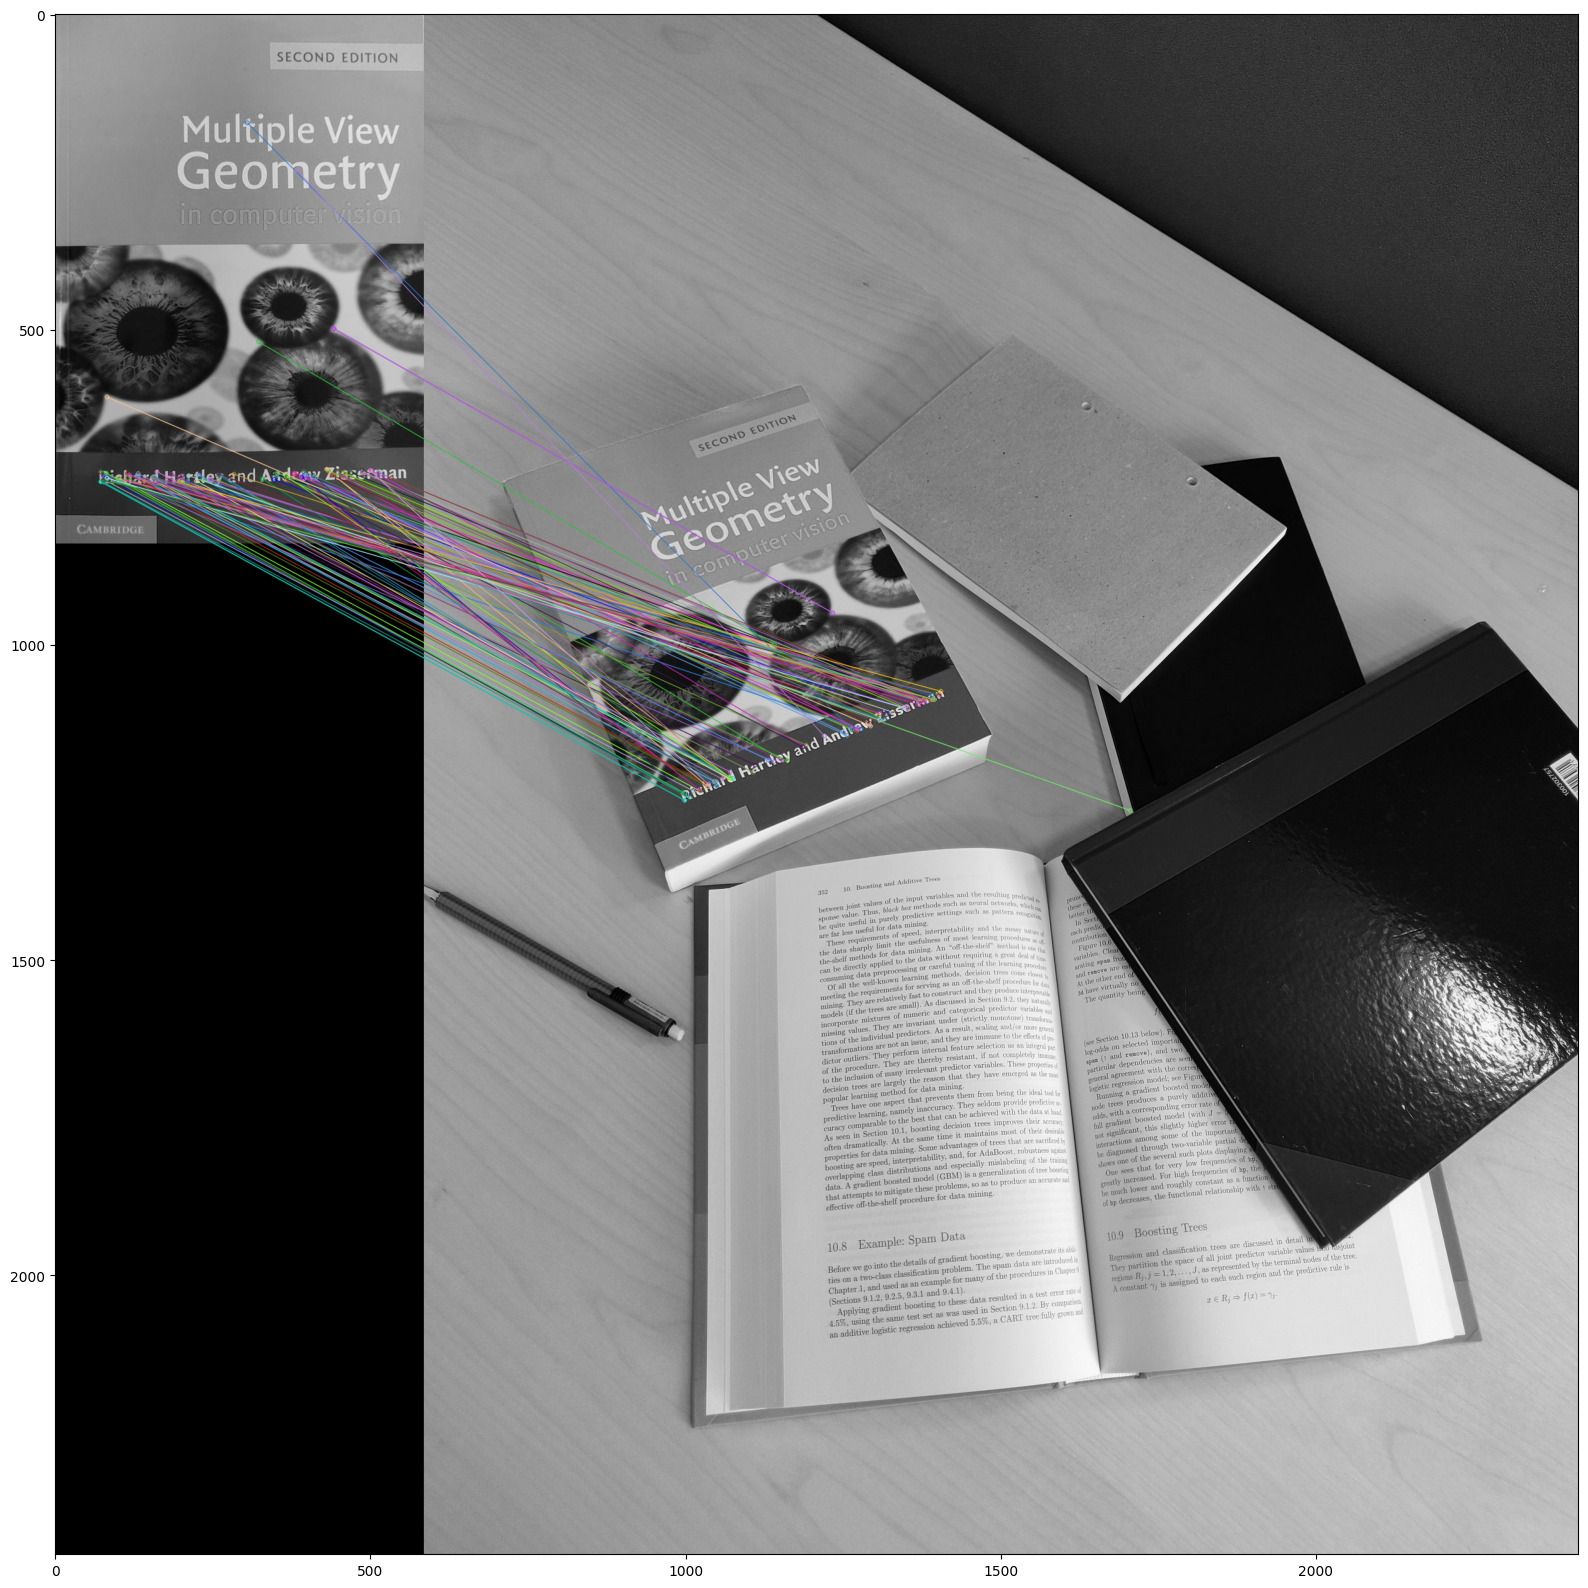

In [18]:
# Oriented FAST and Rotated BRIEF (ORB) is a faster, patent-free alternative to
# SIFT. It combines the FAST corner detector with the BRIEF binary descriptor
# (plus an added orientation component for rotation invariance). ORB descriptors
# are binary strings rather than SIFT's floating-point vectors, which makes them
# much cheaper to compute and compare (at some potential cost to matching
# robustness compared to SIFT), especially under scale or illumination changes.
#   - Reload each image and convert to grayscale (needed for both detectors,
#     same reasoning as before).
#   - cv2.ORB_create() builds an ORB detector with default parameters, and
#     detectAndCompute() finds keypoints + binary descriptors for each image,
#     just like SIFT's detectAndCompute() did.
#   - cv2.drawKeypoints() would let us visualize ORB's keypoints (drawn in blue,
#     color=(0, 0, 255)) the same way as with SIFT.
#   - Matching then proceeds identically to before: cv2.BFMatcher() finds the
#     best correspondence for each descriptor, matches are sorted by distance
#     (best first), and the top 100 are drawn with cv2.drawMatches() for a
#     side-by-side visual comparison against the SIFT result above.
img = cv2.imread("Book.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
orb = cv2.ORB_create()
kp, des = orb.detectAndCompute(gray, None)
image_with_keypoints = cv2.drawKeypoints(img, kp, None, color=(0, 0, 255))
# plt.imshow(cv2.cvtColor(image_with_keypoints, cv2.COLOR_RGB2BGR))

img2 = cv2.imread("More_books.jpg")
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)
kp2, des2 = orb.detectAndCompute(gray2, None)
image2_with_keypoints = cv2.drawKeypoints(img2, kp2, None, color=(0, 0, 255))
# plt.imshow(cv2.cvtColor(image2_with_keypoints, cv2.COLOR_RGB2BGR))

bf = cv2.BFMatcher()
matches = bf.match(des, des2)
matches = sorted(matches, key = lambda x:x.distance)

img3 = cv2.drawMatches(gray, kp, gray2, kp2, matches[:100], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize = (20,20))
plt.imshow(img3)